# Building models with several variables

With many explanatory variables it is not practical to fit a model for every combination of them. We follow a strategy in three steps, comparing nested Cox models with the log-likelihood ratio test.

The data are the survival times, in months, of 48 patients with multiple myeloma, with seven explanatory variables: age, sex (1 = male, 2 = female), blood urea nitrogen (`bun`), serum calcium (`ca`), haemoglobin (`hb`), percentage of plasma cells in the bone marrow (`pcells`) and presence of Bence-Jones protein in the urine (`protein`, 0 = absent, 1 = present).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2
from lifelines import CoxPHFitter

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
opt_color   = '#E69F00'
ref_color   = '#333333'

## The data

In [3]:
DatOriginal = pd.read_csv("data/multiple_myeloma_survival.dat", sep=r"\s+")

In [4]:
DatOriginal.head()

,patient,time,status,age,sex,bun,ca,hb,pcells,protein
0,1,13,1,66,1,25,10,14.6,18,1
1,2,52,0,66,1,13,11,12.0,100,0
2,3,6,1,53,2,15,13,11.4,33,1
3,4,40,1,69,1,10,10,10.2,30,1
4,5,10,1,65,1,20,10,13.2,66,0


## Functions

Function that calculates the test statistic and $P$-value to compare two nested models based on the log-likelihood ratio test.

In [5]:
def LoglikeRatioTest(minus2loglike_model1, minus2loglike_model2, df_model1, df_model2):
    # model1 must be nested in model2, i.e. model2 has more variables than model1
    test_statistic = minus2loglike_model1 - minus2loglike_model2
    p_value = chi2.sf(test_statistic, df_model2-df_model1)
    return test_statistic, p_value

Function that fits a Cox model for each formula and returns the statistic $-2\log\hat L$, the AIC and the number of parameters of each one. With `null=True` the model without variables is added in the first row.

In [6]:
def FitModels(formulas, null=False):
    formulas = list(formulas)

    MinusTwoLogLike = []
    Aic = []
    DegreesFreedom = []

    for i,f in enumerate(formulas):

        cph = CoxPHFitter()
        Model = cph.fit(DatOriginal, 'time', 'status', formula=f)

        if i==0 and null:
            _ = -2*Model.log_likelihood_ + Model.log_likelihood_ratio_test().test_statistic
            MinusTwoLogLike.append(_)
            DegreesFreedom.append(0)
            Aic.append(_)

        MinusTwoLogLike.append(-2*Model.log_likelihood_)
        DegreesFreedom.append(len(Model.summary))
        Aic.append(Model.AIC_partial_)

    if null:
        formulas.insert(0, 'None')

    return pd.DataFrame({'formula': formulas, '-2log-L': MinusTwoLogLike, 'AIC': Aic, 'df': DegreesFreedom})

Function that compares two of the fitted models, given by their formulas.

In [7]:
def CompareModels(formula_model1, formula_model2):
    # model1 must be nested in model2
    model1 = ModelSummary[ModelSummary['formula'] == formula_model1].iloc[0]
    model2 = ModelSummary[ModelSummary['formula'] == formula_model2].iloc[0]
    return np.round(LoglikeRatioTest(model1['-2log-L'], model2['-2log-L'], model1['df'], model2['df']), 3)

## Step 1: one variable at a time

In this case, we have seven explanatory variables, so it becomes intractable to implement models for all the combinations. Thus, we will follow the next strategy.

1. First we fit models that contain each of the variables at a time. The variables that appear important, compared to the Null model are then consider in the subsequent step.

In [8]:
ModelSummary = FitModels(['age', 'sex', 'bun', 'ca', 'hb', 'pcells', 'protein'], null=True)

In [9]:
PValues = []

for i in range(len(ModelSummary)):
    _, Pvalue = LoglikeRatioTest(ModelSummary.loc[0]['-2log-L'], ModelSummary.loc[i]['-2log-L'], 0, ModelSummary.loc[i]['df'])
    PValues.append(Pvalue)

ModelSummary['Pvalue'] = PValues

In [10]:
ModelSummary.round(3)

,formula,-2log-L,AIC,df,Pvalue
0,None,214.678,214.678,0,NaN
1,age,214.541,216.541,1,0.710
2,sex,214.645,216.645,1,0.856
3,bun,205.316,207.316,1,0.002
4,ca,214.204,216.204,1,0.491
5,hb,209.662,211.662,1,0.025
6,pcells,214.601,216.601,1,0.781
7,protein,212.511,214.511,1,0.141


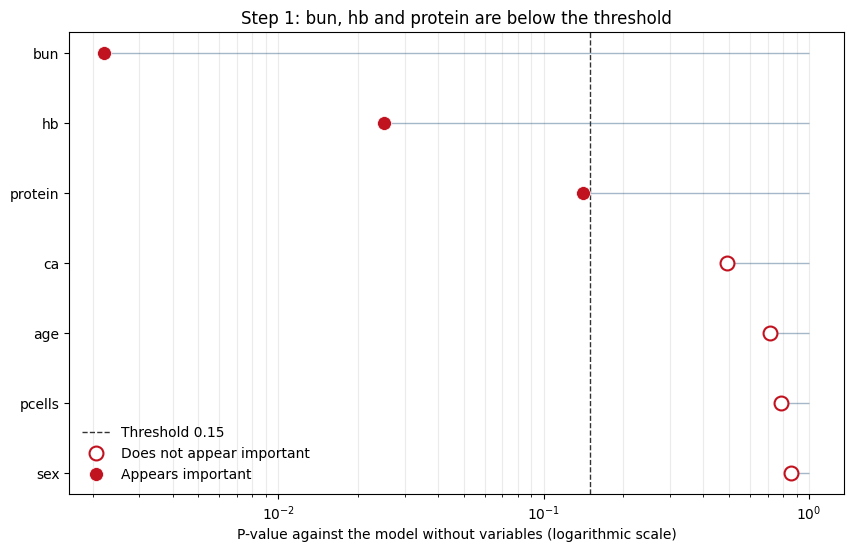

In [11]:
THRESHOLD = 0.15
Single = ModelSummary.iloc[1:].sort_values('Pvalue', ascending=False)
Important = Single['Pvalue'] < THRESHOLD

fig, ax = plt.subplots(figsize=(10, 6))
ax.axvline(THRESHOLD, color=ref_color, lw=1, ls='--', label=f'Threshold {THRESHOLD}')
ax.hlines(Single['formula'], Single['Pvalue'], 1, color=line_color, lw=1, alpha=0.4)
ax.plot(Single.loc[~Important, 'Pvalue'], Single.loc[~Important, 'formula'], 'o', markerfacecolor='white', markersize=10,
        markeredgecolor=point_color, markeredgewidth=1.5, label='Does not appear important')
ax.plot(Single.loc[Important, 'Pvalue'], Single.loc[Important, 'formula'], 'o', color=point_color, markersize=10,
        markeredgecolor='white', markeredgewidth=0.5, label='Appears important')

ax.set_xscale('log')
ax.set_xlabel('P-value against the model without variables (logarithmic scale)')
ax.set_title('Step 1: bun, hb and protein are below the threshold')
ax.legend(loc='lower left', frameon=False)
ax.grid(True, axis='x', which='both', alpha=0.25)

From the previous $P$-values, considering a threshold of 0.15, we deduce that bun, hb and possible protein appear to be important.

## Step 2: the important variables together

2. The variables that appear to be important from step 1 are then fitted together. In the presence of certain variables, others may cease to be important. Those that do not lead to a significant increase in the value of $-2\log \hat{L}$ when omitted can be discarded.

In [12]:
_ = FitModels(['bun+hb', 'bun+protein', 'hb+protein', 'bun+hb+protein'])

ModelSummary = pd.concat([ModelSummary, _], ignore_index=True)

In [13]:
ModelSummary.round(3)

,formula,-2log-L,AIC,df,Pvalue
0,None,214.678,214.678,0,NaN
1,age,214.541,216.541,1,0.710
2,sex,214.645,216.645,1,0.856
3,bun,205.316,207.316,1,0.002
4,ca,214.204,216.204,1,0.491
5,hb,209.662,211.662,1,0.025
6,pcells,214.601,216.601,1,0.781
7,protein,212.511,214.511,1,0.141
8,bun+hb,200.699,204.699,2,NaN
9,bun+protein,200.989,204.989,2,NaN


In [14]:
# Comparing model bun+hb+protein against model bun+hb, i.e. omitting protein
CompareModels('bun+hb', 'bun+hb+protein')
# protein might not be omitted, but let's omit it for now

array([2.798, 0.094])

In [15]:
# Comparing model bun+hb+protein against model bun+protein, i.e. omitting hb
CompareModels('bun+protein', 'bun+hb+protein')
# hb should not be omitted

array([3.087, 0.079])

In [16]:
# Comparing model bun+hb+protein against model hb+protein, i.e. omitting bun
CompareModels('hb+protein', 'bun+hb+protein')
# bun should not be omitted

array([1.0452e+01, 1.0000e-03])

For now, let us omit the variable protein, so we consider just bun and hb.

We now compare the model that has bun and hb with the models that omit any of them.

In [17]:
# Comparing model bun+hb against model bun, i.e. omitting hb
CompareModels('bun', 'bun+hb')
# hb should not be omitted

array([4.617, 0.032])

In [18]:
# Comparing model bun+hb against model hb, i.e. omitting bun
CompareModels('hb', 'bun+hb')
# bun should not be omitted

array([8.963e+00, 3.000e-03])

Neither bun nor hb can be excluded from the model.

## Step 3: adding the other variables

3. Variables that were not important on their own may become important in the presence of others. We add such variables one at a time to the model. Those that reduce $-2\log\hat{L}$ significantly are retained.

In [19]:
_ = FitModels(['bun+hb+age', 'bun+hb+sex', 'bun+hb+ca', 'bun+hb+pcells'])

ModelSummary = pd.concat([ModelSummary, _], ignore_index=True)

In [20]:
ModelSummary.round(3)

,formula,-2log-L,AIC,df,Pvalue
0,None,214.678,214.678,0,NaN
1,age,214.541,216.541,1,0.710
2,sex,214.645,216.645,1,0.856
3,bun,205.316,207.316,1,0.002
4,ca,214.204,216.204,1,0.491
5,hb,209.662,211.662,1,0.025
6,pcells,214.601,216.601,1,0.781
7,protein,212.511,214.511,1,0.141
8,bun+hb,200.699,204.699,2,NaN
9,bun+protein,200.989,204.989,2,NaN


In [21]:
# Comparing model bun+hb against model bun+hb+age, i.e. adding age
CompareModels('bun+hb', 'bun+hb+age')
# age should not be added

array([0.246, 0.62 ])

In [22]:
# Comparing model bun+hb against model bun+hb+sex, i.e. adding sex
CompareModels('bun+hb', 'bun+hb+sex')
# sex should not be added

array([0.393, 0.531])

In [23]:
# Comparing model bun+hb against model bun+hb+ca, i.e. adding ca
CompareModels('bun+hb', 'bun+hb+ca')
# ca should not be added

array([0.001, 0.979])

In [24]:
# Comparing model bun+hb against model bun+hb+pcells, i.e. adding pcells
CompareModels('bun+hb', 'bun+hb+pcells')
# pcells should not be added

array([0.225, 0.635])

## Keeping protein

When we compare the models bun+hb+protein and bun+hb, we got a $P$-value of 0.094. So, there is a slight evidence that the models are different, and we can decide to keep protein instead of omitting it.

Let's keep it now, and add each of the variables that where considered as unimportant.

In [25]:
_ = FitModels(['bun+hb+protein+age', 'bun+hb+protein+sex', 'bun+hb+protein+ca', 'bun+hb+protein+pcells'])

ModelSummary = pd.concat([ModelSummary, _], ignore_index=True)

In [26]:
ModelSummary.round(3)

,formula,-2log-L,AIC,df,Pvalue
0,None,214.678,214.678,0,NaN
1,age,214.541,216.541,1,0.710
2,sex,214.645,216.645,1,0.856
3,bun,205.316,207.316,1,0.002
4,ca,214.204,216.204,1,0.491
5,hb,209.662,211.662,1,0.025
6,pcells,214.601,216.601,1,0.781
7,protein,212.511,214.511,1,0.141
8,bun+hb,200.699,204.699,2,NaN
9,bun+protein,200.989,204.989,2,NaN


In [27]:
# Comparing model bun+hb+protein against model bun+hb+protein+age, i.e. adding age
CompareModels('bun+hb+protein', 'bun+hb+protein+age')
# age should not be added

array([0.299, 0.584])

In [28]:
# Comparing model bun+hb+protein against model bun+hb+protein+sex, i.e. adding sex
CompareModels('bun+hb+protein', 'bun+hb+protein+sex')
# sex should not be added

array([0.327, 0.568])

In [29]:
# Comparing model bun+hb+protein against model bun+hb+protein+ca, i.e. adding ca
CompareModels('bun+hb+protein', 'bun+hb+protein+ca')
# ca should not be added

array([0.04 , 0.842])

In [30]:
# Comparing model bun+hb+protein against model bun+hb+protein+pcells, i.e. adding pcells
CompareModels('bun+hb+protein', 'bun+hb+protein+pcells')
# pcells should not be added

array([0.   , 0.985])

## The chosen model

Thus, we prefer the model that includes the variables bun, hb, and protein.

Furthermore, we can also look at the AIC, which give the same suggestion.

Ultimately, one might wish to include protein in the model so as not to miss anything.

In [31]:
ModelSummary.iloc[ModelSummary['AIC'].argmin()]

formula    bun+hb+protein
-2log-L        197.901273
AIC            203.901273
df                      3
Pvalue                NaN
Name: 11, dtype: object

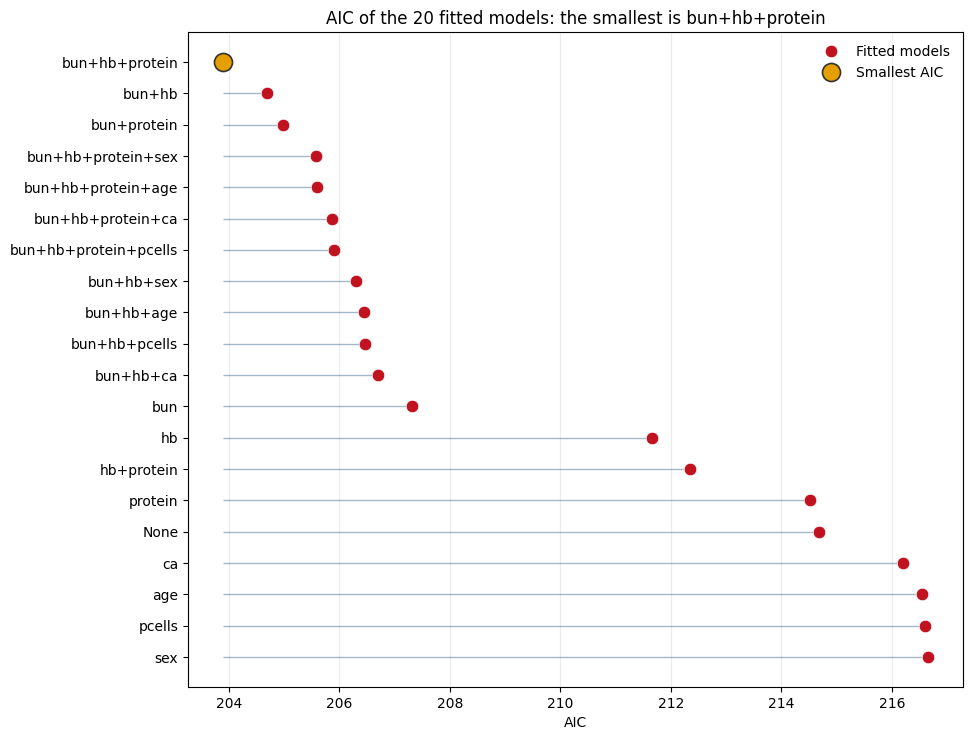

In [32]:
Sorted = ModelSummary.sort_values('AIC', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 8.5))
ax.hlines(Sorted.index, Sorted['AIC'].min(), Sorted['AIC'], color=line_color, lw=1, alpha=0.4)
ax.plot(Sorted['AIC'], Sorted.index, 'o', color=point_color, markersize=9, markeredgecolor='white', markeredgewidth=0.5,
        label='Fitted models')
ax.plot(Sorted['AIC'].iloc[-1], Sorted.index[-1], 'o', color=opt_color, markersize=13, markeredgecolor=ref_color,
        markeredgewidth=1.2, label='Smallest AIC', zorder=5)

ax.set_yticks(Sorted.index, Sorted['formula'])
ax.set_xlabel('AIC')
ax.set_title(f"AIC of the {len(Sorted)} fitted models: the smallest is {Sorted['formula'].iloc[-1]}")
ax.legend(loc='upper right', frameon=False)
ax.grid(True, axis='x', alpha=0.25)

Hazard ratios of the chosen model, with their 95% confidence intervals: the hazard increases with bun; it is estimated to be lower with more hb and when the protein is present, although those two intervals reach 1.

In [33]:
ModelChosen = CoxPHFitter().fit(DatOriginal, 'time', 'status', formula='bun+hb+protein')
ModelChosen.print_summary()

<lifelines.CoxPHFitter: fitted with 48 total observations, 12 right-censored observations>
             duration col = 'time'
                event col = 'status'
      baseline estimation = breslow
   number of observations = 48
number of events observed = 36
   partial log-likelihood = -98.95
         time fit was run = 2026-10-13 02:24:31 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
bun        0.02      1.02      0.01            0.01            0.03                1.01                1.03
hb        -0.11      0.90      0.06           -0.23            0.01                0.79                1.01
protein   -0.66      0.52      0.41           -1.46            0.14                0.23                1.15

           cmp to     z      p  -log2(p)
covariate                               
bun          0.00  3.72 <0.005     12.29
hb           0.00 -1.77   0.08      3.70
protein      0.00 -1.63   0.10      3.27
---
Concordance = 0.70
Partial AIC = 203.90
log-likelihood ratio test = 16.78 on 3 df
-log2(p) of ll-ratio test = 10.31

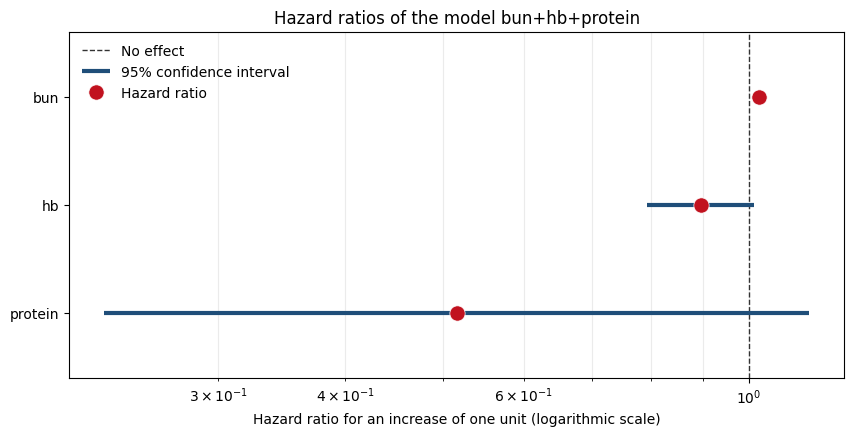

In [34]:
Summary = ModelChosen.summary
position = np.arange(len(Summary))[::-1]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvline(1, color=ref_color, lw=1, ls='--', label='No effect')
ax.hlines(position, Summary['exp(coef) lower 95%'], Summary['exp(coef) upper 95%'], color=line_color, lw=3,
          label='95% confidence interval')
ax.plot(Summary['exp(coef)'], position, 'o', color=point_color, markersize=11, markeredgecolor='white',
        markeredgewidth=0.5, label='Hazard ratio')
ax.set_yticks(position, Summary.index)
ax.set_ylim(-0.6, len(Summary)-0.4)
ax.set_xscale('log')
ax.set_xlabel('Hazard ratio for an increase of one unit (logarithmic scale)')
ax.set_title('Hazard ratios of the model bun+hb+protein')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, axis='x', which='both', alpha=0.25)